In [12]:
from collections import defaultdict
import matplotlib.pyplot as plt
from copy import deepcopy
import io
import numpy as np
import math
from collections import defaultdict, namedtuple
import itertools
import subprocess


In [2]:
######################################### START OF INPUT ####################################
MAX_L = 2
######################################### END   OF INPUT ####################################

In [3]:

Node = tuple  # (a,b,c,d,m)

Candidate = namedtuple("Candidate", ["nodeset", "Lsums", "cost", "rule", "child_refs"])

# children generation
def _children_for_rule(node: Node, rule: str):
    a,b,c,d,m = node
    if rule == "A":
        candidates = [
            (a-1,b,c,d,m),
            (a-1,b,c,d,m+1),
            (a-2,b,c,d,m),
            (a-2,b,c,d,m+1),
            (a-1,b-1,c,d,m),
            (a-1,b-1,c,d,m+1),
            (a-1,b,c,d-1,m+1),
            (a-1,b,c-1,d,m+1)
        ]
    elif rule == "B":
        candidates = [
            (a,b-1,c,d,m),
            (a,b-1,c,d,m+1),
            (a,b-2,c,d,m),
            (a,b-2,c,d,m+1),
            (a-1,b-1,c,d,m),
            (a-1,b-1,c,d,m+1),
            (a,b-1,c,d-1,m+1),
            (a,b-1,c-1,d,m+1)
        ]
    elif rule == "C":
        candidates = [
            (a,b,c-1,d,m),
            (a,b,c-1,d,m+1),
            (a,b,c-2,d,m),
            (a,b,c-2,d,m+1),
            (a,b,c-1,d-1,m),
            (a,b,c-1,d-1,m+1),
            (a-1,b,c-1,d,m+1),
            (a,b-1,c-1,d,m+1)
        ]
    elif rule == "D":
        candidates = [
            (a,b,c,d-1,m),
            (a,b,c,d-1,m+1),
            (a,b,c,d-2,m),
            (a,b,c,d-2,m+1),
            (a,b,c-1,d-1,m),
            (a,b,c-1,d-1,m+1),
            (a-1,b,c,d-1,m+1),
            (a,b-1,c,d-1,m+1),
        ]
    else:
        raise ValueError("Unknown rule")
    filtered = [t for t in candidates if t[0] >= 0 and t[1] >= 0 and t[2] >= 0 and t[3] >= 0]
    return filtered

def L_of(node: Node):
    return node[0] + node[1] + node[2] + node[3]

def weight_of(node: Node):
    a,b,c,d,m = node
    return m*(a+1)*(b+1)*(c+1)*(d+1)*(a+2)*(b+2)*(c+2)*(d+2)//16

def is_base(node: Node):
    return node[0] == 0 and node[1] == 0 and node[2] == 0 and node[3] == 0

xyz_idx = defaultdict(lambda: defaultdict(int))
idx_xyz = defaultdict(lambda: defaultdict(int))


def name_cart( x,y,z ):
    ret = ""
    if x + y + z == 0:
        return 's'

    for _ in range(x):
        ret += 'x'
    for _ in range(y):
        ret += 'y'
    for _ in range(z):
        ret += 'z'
    return ret

def nl(l):
    return (l+1)*(l+2)//2

def snl(l):
    s = 0
    for i in range(l):
        s += (l+1)*(l+2)//2
    return s

for l in range(12):
    y = 0
    z = 0
    max_z = 0
    idx_xyz[l] = defaultdict(int)
    xyz_idx[l] = defaultdict(int)
    for i in range ( nl(l)):
        x = l - y - z
        idx_xyz[l][(x,y,z)] = i
        xyz_idx[l][i] = (x,y,z)

        z += 1
        y -= 1
        if z > max_z:
            z = 0
            max_z += 1
            y = max_z

orb = ['s','p','d','f','g']




In [4]:
def cost_fn( node, rule ):
    a,b,c,d,m = node
    # directional penalty
    if rule == "A":
        loc = (b+1)*(c+1)*(d+1)*(b+2)*(c+2)*(d+2)//8
    elif rule == "B":
        loc = (c+1)*(d+1)*(c+2)*(d+2)//4
    elif rule == "C":
        loc = (d+1)*(d+2)//2
    elif rule == "D":
        loc = 0
    else:
        loc = 0
        
    return (a+1)*(b+1)*(c+1)*(d+1)*(a+2)*(b+2)*(c+2)*(d+2)//16 + loc
    
def best_strategy(target):

    from functools import lru_cache

    choice = {}

    @lru_cache(None)
    def F(node):
        a,b,c,d,m = node

        if a == b == c == d == 0:
            return cost_fn(node, rules[0] )

        best = float('inf')
        best_rule = None

        for r in rules:
            children = _children_for_rule(node, r)
            if not children:
                continue

            total = cost_fn(node, r )
            for child in children:
                total += F(child)

            if total < best:
                best = total
                best_rule = r

        choice[node] = best_rule
        return best

    F(target)
    return choice

def build_optimal_order(target, choice):

    visited = set()
    order = []

    def dfs(node):
        if node in visited:
            return
        visited.add(node)

        rule = choice.get(node)
        if rule is not None:
            for child in _children_for_rule(node, rule):
                dfs(child)

        order.append((node, rule))

    dfs(target)
    return order
    

def compress_path(path):
    """
    path: list of ((a,b,c,d,m), r)
    """

    groups = defaultdict(list)

    for (a,b,c,d,m), r in path:

        # skip bases
        if (a,b,c,d) == (0,0,0,0):
            continue

        key = (a,b,c,d,r)
        groups[key].append(m)

    result = []

    for (a,b,c,d,r), m_values in groups.items():
        m_min = min(m_values)
        m_max = max(m_values)
        span  = m_max - m_min + 1

        result.append((a+b+c+d,a,b,c,d,m_min,m_max,span,r))

    # optional: sort for readability
    result.sort()

    return result


In [5]:

def name4( la,lb,lc,ld ):
    return orb[la] + orb[lb] + orb[lc] + orb[ld]

def idx4( i,la, j,lb, k,lc, l,ld, m,M, p,P ):
    return i*nl(lb)*nl(lc)*nl(ld)*M*P + j*nl(lc)*nl(ld)*M*P + k*nl(ld)*M*P + l*M*P + m*P + p

def AL_solver( i,la, j, lb, k,lc, l,ld ):

#    print('Calling AL solver i LA j LB | k LC l LD : ', i,la, j, lb,'|', k,lc, l,ld )
    
    a = ax,ay,az = xyz_idx[la][i]
    b = bx,by,bz = xyz_idx[lb][j]
    c = cx,cy,cz = xyz_idx[lc][k]
    d = dx,dy,dz = xyz_idx[ld][l]

    if ax > 0:
        Updir = 0
        am = ax-1,ay,az
        bm = bx-1,by,bz
        cm = cx-1,cy,cz
        dm = dx-1,dy,dz
        aw = ax-2,ay,az
        na=ax-1; nb=bx; nc=cx; nd=dx
    elif ay > 0:
        Updir = 1
        am = ax,ay-1,az
        bm = bx,by-1,bz
        cm = cx,cy-1,cz
        dm = dx,dy-1,dz
        aw = ax,ay-2,az
        na=ay-1; nb=by; nc=cy; nd=dy
    else:
        Updir = 2
        am = ax,ay,az-1
        bm = bx,by,bz-1
        cm = cx,cy,cz-1
        dm = dx,dy,dz-1
        aw = ax,ay,az-2
        na=az-1; nb=bz; nc=cz; nd=dz    
#    print('Retuning AL solver Dir | ABCD | MMMM | W | N : ', Updir, '|', a,b,c,d, '|', am,bm,cm,dm, '|', aw, '|', na,nb,nc,nd )
    return Updir, a,b,c,d, am,bm,cm,dm, aw, na,nb,nc,nd
    
def BL_solver( i,la, j, lb, k,lc, l,ld ):
    a = ax,ay,az = xyz_idx[la][i]
    b = bx,by,bz = xyz_idx[lb][j]
    c = cx,cy,cz = xyz_idx[lc][k]
    d = dx,dy,dz = xyz_idx[ld][l]

    if bx > 0:
        Updir = 0
        am = ax-1,ay,az
        bm = bx-1,by,bz
        cm = cx-1,cy,cz
        dm = dx-1,dy,dz
        bw = bx-2,by,bz
        na=ax; nb=bx-1; nc=cx; nd=dx
    elif by > 0:
        Updir = 1
        am = ax,ay-1,az
        bm = bx,by-1,bz
        cm = cx,cy-1,cz
        dm = dx,dy-1,dz
        bw = bx,by-2,bz
        na=ay; nb=by-1; nc=cy; nd=dy
    else:
        Updir = 2
        am = ax,ay,az-1
        bm = bx,by,bz-1
        cm = cx,cy,cz-1
        dm = dx,dy,dz-1
        bw = bx,by,bz-2
        na=az; nb=bz-1; nc=cz; nd=dz    
       
    return Updir, a,b,c,d, am,bm,cm,dm, bw, na,nb,nc,nd

def CL_solver( i,la, j, lb, k,lc, l,ld ):
    a = ax,ay,az = xyz_idx[la][i]
    b = bx,by,bz = xyz_idx[lb][j]
    c = cx,cy,cz = xyz_idx[lc][k]
    d = dx,dy,dz = xyz_idx[ld][l]

    if cx > 0:
        Updir = 0
        am = ax-1,ay,az
        bm = bx-1,by,bz
        cm = cx-1,cy,cz
        dm = dx-1,dy,dz
        cw = cx-2,cy,cz
        na=ax; nb=bx; nc=cx-1; nd=dx
    elif cy > 0:
        Updir = 1
        am = ax,ay-1,az
        bm = bx,by-1,bz
        cm = cx,cy-1,cz
        dm = dx,dy-1,dz
        cw = cx,cy-2,cz
        na=ay; nb=by; nc=cy-1; nd=dy
    else:
        Updir = 2
        am = ax,ay,az-1
        bm = bx,by,bz-1
        cm = cx,cy,cz-1
        dm = dx,dy,dz-1
        cw = cx,cy,cz-2
        na=az; nb=bz; nc=cz-1; nd=dz    
       
    return Updir, a,b,c,d, am,bm,cm,dm, cw, na,nb,nc,nd

def DL_solver( i,la, j, lb, k,lc, l,ld ):
    a = ax,ay,az = xyz_idx[la][i]
    b = bx,by,bz = xyz_idx[lb][j]
    c = cx,cy,cz = xyz_idx[lc][k]
    d = dx,dy,dz = xyz_idx[ld][l]

    if dx > 0:
        Updir = 0
        am = ax-1,ay,az
        bm = bx-1,by,bz
        cm = cx-1,cy,cz
        dm = dx-1,dy,dz
        dw = dx-2,dy,dz
        na=ax; nb=bx; nc=cx; nd=dx-1
    elif dy > 0:
        Updir = 1
        am = ax,ay-1,az
        bm = bx,by-1,bz
        cm = cx,cy-1,cz
        dm = dx,dy-1,dz
        dw = dx,dy-2,dz
        na=ay; nb=by; nc=cy; nd=dy-1
    else:
        Updir = 2
        am = ax,ay,az-1
        bm = bx,by,bz-1
        cm = cx,cy,cz-1
        dm = dx,dy,dz-1
        dw = bx,by,bz-2
        na=az; nb=bz; nc=cz; nd=dz-1
       
    return Updir, a,b,c,d, am,bm,cm,dm, dw, na,nb,nc,nd

def idx( i,j,k,l,m,p, la,lb,lc,ld, idx ):
    return name4( la,lb,lc,ld ) +'['+idx+'('+str(i)+','+str(j)+','+str(k)+','+str(l)+','+str(m)+','+str(p)+')]'
    
def gen( target, la,lb,lc,ld, start_m,end_m,ldM, M_m,M_w,M_n,M_c,M_k, S_m,S_w,S_n,S_c,S_k, P, Up, output_buffer ):
    
    nla = nl(la)
    nlb = nl(lb)
    nlc = nl(lc)
    nld = nl(ld)
    
    print( '// For ', name4(*target[:-1]), ' : step ', name4( la,lb,lc,ld ) , ' in direction ', Up, '. m goes from ', start_m, 'to', end_m, end='', file=output_buffer )
    print( '// ldMs are : ', ldM,M_m,M_w,M_n,M_c,M_k, file=output_buffer )
    print( '// Mstart are : ', start_m,S_m,S_w,S_n,S_c,S_k, file=output_buffer )
#    print( '// target | L | M | MMs | D ', target, "|", la,lb,lc,ld,"|", start_m,end_m,ldM,M_m,M_w,M_n,M_c,M_k, P, "|", Up)
    
#    print( f"#define IDX0(i,j,k,l,m,p) ((((( i*{nlb}+j)*{nlc}+k)*{nld}+l)*{M_0000}+m)*{P}+p)" )
#    print( f"#define IDXM(i,j,k,l,m,p) ((((( i*{nlb}+j)*{nlc}+k)*{nld}+l)*{M_m000}+m)*{P}+p)" )
#    print( f"#define IDXW(i,j,k,l,m,p) ((((( i*{nlb}+j)*{nlc}+k)*{nld}+l)*{M_w000}+m)*{P}+p)" )
#    print( f"#define IDXN(i,j,k,l,m,p) ((((( i*{nlb}+j)*{nlc}+k)*{nld}+l)*{M_mm00}+m)*{P}+p)" )
#    print( f"#define IDXC(i,j,k,l,m,p) ((((( i*{nlb}+j)*{nlc}+k)*{nld}+l)*{M_m0m0}+m)*{P}+p)" )
#    print( f"#define IDXK(i,j,k,l,m,p) ((((( i*{nlb}+j)*{nlc}+k)*{nld}+l)*{M_m00m}+m)*{P}+p)" )
                        
#                        name_m00000 = name4( la-1,lb,lc,ld )
#                        idx_PA = idx( idx_xyz[la-1][am], idx_xyz[lb][b], idx_xyz[lc][c], idx_xyz[ld][d],m  ,0, la-1,lb,lc,ld,'IDX1' )
#                        idx_WP = idx( idx_xyz[la-1][am], idx_xyz[lb][b], idx_xyz[lc][c], idx_xyz[ld][d],m+1,0, la-1,lb,lc,ld,'IDX1' )

    print( "const int ", name4(*target[:-1]), "_", name4( la,lb,lc,ld ),"_info[] = { ",sep='' , file=output_buffer)
    print("    ",end="", file=output_buffer)
    n_list = []
    ijkl = 0
    for i in range(nla):
        for j in range(nlb):
            for k in range(nlc):
                for l in range(nld):
                    
                    m = start_m
                    p = 0
                
                    if Up == 'A':
                        di, a,b,c,d, am,bm,cm,dm, aw, na,nb,nc,nd = AL_solver( i,la, j, lb, k,lc, l,ld )
                        nw, nn, nc, nk = na,nb,nc,nd                        
                        idx_0 = idx4( idx_xyz[la][a], la, idx_xyz[lb][b], lb, idx_xyz[lc][c], lc, idx_xyz[ld][d], ld, m  , ldM, p,P )
                        idx_m = idx4( idx_xyz[la-1][am], la-1, idx_xyz[lb][b], lb, idx_xyz[lc][c], lc, idx_xyz[ld][d], ld, m-S_m  , M_m, p,P )
                        idx_w = idx4( idx_xyz[la-2][aw], la-2, idx_xyz[lb][b], lb, idx_xyz[lc][c], lc, idx_xyz[ld][d], ld, m-S_w  , M_w, p,P )
                        idx_n = idx4( idx_xyz[la-1][am], la-1, idx_xyz[lb-1][bm], lb-1, idx_xyz[lc][c], lc, idx_xyz[ld][d], ld, m-S_n  , M_n, p,P )
                        idx_c = idx4( idx_xyz[la-1][am], la-1, idx_xyz[lb][b], lb, idx_xyz[lc-1][cm], lc-1, idx_xyz[ld][d], ld, m+1-S_c, M_c, p,P )
                        idx_k = idx4( idx_xyz[la-1][am], la-1, idx_xyz[lb][b], lb, idx_xyz[lc][c], lc, idx_xyz[ld-1][dm], ld-1, m+1-S_k, M_k, p,P )                        
                    if Up == 'B':
                        di, a,b,c,d, am,bm,cm,dm, bw, na,nb,nc,nd = BL_solver( i,la, j, lb, k,lc, l,ld )
                        nw, nn, nc, nk = nb,na,nc,nd
                        idx_0 = idx4( idx_xyz[la][a], la, idx_xyz[lb][b], lb, idx_xyz[lc][c], lc, idx_xyz[ld][d], ld, m  , ldM, p,P )
                        idx_m = idx4( idx_xyz[la][a], la, idx_xyz[lb-1][bm], lb-1, idx_xyz[lc][c], lc, idx_xyz[ld][d], ld, m-S_m  , M_m, p,P )
                        idx_w = idx4( idx_xyz[la][a], la, idx_xyz[lb-2][bw], lb-2, idx_xyz[lc][c], lc, idx_xyz[ld][d], ld, m-S_w  , M_w, p,P )
                        idx_n = idx4( idx_xyz[la-1][am], la-1, idx_xyz[lb-1][bm], lb-1, idx_xyz[lc][c], lc, idx_xyz[ld][d], ld, m-S_n  , M_n, p,P )
                        idx_c = idx4( idx_xyz[la][a], la, idx_xyz[lb-1][bm], lb-1, idx_xyz[lc-1][cm], lc-1, idx_xyz[ld][d], ld, m+1-S_c, M_c, p,P )
                        idx_k = idx4( idx_xyz[la][a], la, idx_xyz[lb-1][bm], lb-1, idx_xyz[lc][c], lc, idx_xyz[ld-1][dm], ld-1, m+1-S_k, M_k, p,P )
                    if Up == 'C':
                        di, a,b,c,d, am,bm,cm,dm, cw, na,nb,nc,nd = CL_solver( i,la, j, lb, k,lc, l,ld )
                        nw, nn, nc, nk = nc,nd,na,nb
                        idx_0 = idx4( idx_xyz[la][a], la, idx_xyz[lb][b], lb, idx_xyz[lc][c], lc, idx_xyz[ld][d], ld, m  , ldM, p,P )
                        idx_m = idx4( idx_xyz[la][a], la, idx_xyz[lb][b], lb, idx_xyz[lc-1][cm], lc-1, idx_xyz[ld][d], ld, m-S_m  , M_m, p,P )
                        idx_w = idx4( idx_xyz[la][a], la, idx_xyz[lb][b], lb, idx_xyz[lc-2][cw], lc-2, idx_xyz[ld][d], ld, m-S_w  , M_w, p,P )
                        idx_n = idx4( idx_xyz[la][a], la, idx_xyz[lb][b], lb, idx_xyz[lc-1][cm], lc-1, idx_xyz[ld-1][dm], ld-1, m-S_n  , M_n, p,P )
                        idx_c = idx4( idx_xyz[la-1][am], la-1, idx_xyz[lb][b], lb, idx_xyz[lc-1][cm], lc-1, idx_xyz[ld][d], ld, m+1-S_c, M_c, p,P )
                        idx_k = idx4( idx_xyz[la][a], la, idx_xyz[lb-1][bm], lb-1, idx_xyz[lc-1][cm], lc-1, idx_xyz[ld][d], ld, m+1-S_k, M_k, p,P )
                    if Up == 'D':
                        di, a,b,c,d, am,bm,cm,dm, dw, na,nb,nc,nd = DL_solver( i,la, j, lb, k,lc, l,ld )
                        nw, nn, nc, nk = nd,nc,na,nb
                        idx_0 = idx4( idx_xyz[la][a], la, idx_xyz[lb][b], lb, idx_xyz[lc][c], lc, idx_xyz[ld][d], ld, m  , ldM, p,P )
                        idx_m = idx4( idx_xyz[la][a], la, idx_xyz[lb][b], lb, idx_xyz[lc][c], lc, idx_xyz[ld-1][dm], ld-1, m-S_m  , M_m, p,P )
                        idx_w = idx4( idx_xyz[la][a], la, idx_xyz[lb][b], lb, idx_xyz[lc][c], lc, idx_xyz[ld-2][dw], ld-2, m-S_w  , M_w, p,P )
                        idx_n = idx4( idx_xyz[la][a], la, idx_xyz[lb][b], lb, idx_xyz[lc-1][cm], lc-1, idx_xyz[ld-1][dm], ld-1, m-S_n  , M_n, p,P )
                        idx_c = idx4( idx_xyz[la-1][am], la-1, idx_xyz[lb][b], lb, idx_xyz[lc][c], lc, idx_xyz[ld-1][dm], ld-1, m+1-S_c, M_c, p,P )
                        idx_k = idx4( idx_xyz[la][a], la, idx_xyz[lb-1][bm], lb-1, idx_xyz[lc][c], lc, idx_xyz[ld-1][dm], ld-1, m+1-S_k, M_k, p,P )

#                    print( di, idx_m, idx_w, idx_n, idx_c, idx_k, sep=',' )
                    
                    di = np.clip( di, 0, 2 )
                    idx_m = np.clip( idx_m, 0, None )
                    idx_w = np.clip( idx_w, 0, None )
                    idx_n = np.clip( idx_n, 0, None )
                    idx_c = np.clip( idx_c, 0, None )
                    idx_k = np.clip( idx_k, 0, None )
                    nw = np.clip( nw, 0, None )
                    nn = np.clip( nn, 0, None )
                    nc = np.clip( nc, 0, None )
                    nk = np.clip( nk, 0, None )

                    print( di, idx_m, idx_w, idx_n, idx_c, idx_k, sep=',' , end=' ', file=output_buffer)
                    if ( i != nla-1 or j != nlb-1 or k != nlc-1 or l != nld-1 ):
                        print(',',end=" ", file=output_buffer)
                    if ( ijkl % 4 == 3 ):
                        print("", file=output_buffer)
                        print("    ",end="", file=output_buffer)
                    n_list.append( (nw,nn,nc,nk) )
                    ijkl += 1
                    
    print( '};' , file=output_buffer)
    print( "const double "+ name4(*target[:-1])+"_"+name4( la,lb,lc,ld )+"_n[] = {" , file=output_buffer)
    print("    ",end="", file=output_buffer)
    for i in range(len(n_list)):
        n4 = n_list[i]
        for j in range(4):
            print( n4[j], end="" , file=output_buffer)
            if i != len(n_list)-1 or j != 3:
                print( ',', end='', file=output_buffer)
        print( ' ', end='', file=output_buffer)
        if i % 4 == 3:
            print("", file=output_buffer)
            print("    ",end="", file=output_buffer)

    print("};", file=output_buffer)
        
def get_ldM_from_path( target, path ):
    ldMs = defaultdict(int)
    minM = defaultdict(int)
    ldMs[(0,0,0,0)] = target[0] + target[1] + target[2] + target[3] + 1
    minM[(0,0,0,0)] = 0
    for (L,la,lb,lc,ld,m_start,m_end,ldM,r) in path:
        ldMs[(la,lb,lc,ld)] = ldM
        minM[(la,lb,lc,ld)] = m_start
    return ldMs, minM

def assign_to_buffer( target, path, ldM_of, minM_of, output_buffer  ):
    mem_by_L = defaultdict(int)
    mem = defaultdict(int)
    
    print("#ifndef DEFINE_GUARD_"+name4(*target[:-1])+"_H", file=output_buffer)
    print("#define DEFINE_GUARD_"+name4(*target[:-1])+"_H", file=output_buffer)
    
    mem_by_L[0] += target[0] + target[1] + target[2] + target[3] + 1
    mem[ (0,0,0,0) ] = 0
    for (L,la,lb,lc,ld,m_start,m_end,ldM,r) in path[:-1]:
        mem_by_L[L] += weight_of( (la,lb,lc,ld,ldM) )
    print( '// Mem by L', dict(mem_by_L) , file=output_buffer)
        
    mem_by_3L = defaultdict(int)
    for L, m in mem_by_L.items():
        mem_by_3L[(L)%3] = max( mem_by_3L[(L)%3], m )
    print( '// Mem by buffer: ', dict(mem_by_3L) , file=output_buffer)
    
    mem_tmp_by_L = defaultdict(int)
    for (L,la,lb,lc,ld,m_start,m_end,ldM,r) in path[:-1]:
        mem_start = 0
        if (L)%3 == 1 :
            mem_start += mem_by_3L[0]
        if (L)%3 == 2 :
            mem_start += mem_by_3L[0] + mem_by_3L[1]
        mem[(la,lb,lc,ld)] = mem_start + mem_tmp_by_L[L]
        mem_tmp_by_L[L] += weight_of( (la,lb,lc,ld,ldM) )

    for labcd in sorted(mem.keys()):
        print( '// Mem ', labcd, mem[labcd] , file=output_buffer)

    tot_buf_mem = sum([ mem_by_3L[x] for x in mem_by_3L] )
    return mem_by_L, mem, tot_buf_mem

def bool_to_lower( b ):
    if b : return "true"
    return "false"




def generate_info_n( target, path, ldM_of, minM_of, output_buffer): 
    P = 1
    for (L,la,lb,lc,ld,m_start,m_end,ldM,r) in path:
        if r == 'A':
            M_m,M_w = ldM_of[(la-1,lb,lc,ld)], ldM_of[(la-2,lb,lc,ld)]
            M_n,M_c,M_k = ldM_of[(la-1,lb-1,lc,ld)], ldM_of[(la-1,lb,lc-1,ld)], ldM_of[(la-1,lb,lc,ld-1)]
            S_m,S_w = minM_of[(la-1,lb,lc,ld)], minM_of[(la-2,lb,lc,ld)]
            S_n,S_c,S_k = minM_of[(la-1,lb-1,lc,ld)], minM_of[(la-1,lb,lc-1,ld)], minM_of[(la-1,lb,lc,ld-1)]
        if r == 'B':
            M_m,M_w = ldM_of[(la,lb-1,lc,ld)], ldM_of[(la,lb-2,lc,ld)]
            M_n,M_c,M_k = ldM_of[(la-1,lb-1,lc,ld)], ldM_of[(la,lb-1,lc-1,ld)], ldM_of[(la,lb-1,lc,ld-1)]
            S_m,S_w = minM_of[(la,lb-1,lc,ld)], minM_of[(la,lb-2,lc,ld)]
            S_n,S_c,S_k = minM_of[(la-1,lb-1,lc,ld)], minM_of[(la,lb-1,lc-1,ld)], minM_of[(la,lb-1,lc,ld-1)]
        if r == 'C':
            M_m,M_w = ldM_of[(la,lb,lc-1,ld)], ldM_of[(la,lb,lc-2,ld)]
            M_n,M_c,M_k = ldM_of[(la,lb,lc-1,ld-1)], ldM_of[(la-1,lb,lc-1,ld)], ldM_of[(la,lb-1,lc-1,ld)]
            S_m,S_w = minM_of[(la,lb,lc-1,ld)], minM_of[(la,lb,lc-2,ld)]
            S_n,S_c,S_k = minM_of[(la,lb,lc-1,ld-1)], minM_of[(la-1,lb,lc-1,ld)], minM_of[(la,lb-1,lc-1,ld)]
        if r == 'D':
            M_m,M_w = ldM_of[(la,lb,lc,ld-1)], ldM_of[(la,lb,lc,ld-2)]
            M_n,M_c,M_k = ldM_of[(la,lb,lc-1,ld-1)], ldM_of[(la-1,lb,lc,ld-1)], ldM_of[(la,lb-1,lc,ld-1)]
            S_m,S_w = minM_of[(la,lb,lc,ld-1)], minM_of[(la,lb,lc,ld-2)]
            S_n,S_c,S_k = minM_of[(la,lb,lc-1,ld-1)], minM_of[(la-1,lb,lc,ld-1)], minM_of[(la,lb-1,lc,ld-1)]
        
        gen( target, la,lb,lc,ld, m_start,m_end,ldM, M_m,M_w,M_n,M_c,M_k, S_m,S_w,S_n,S_c,S_k,  P,r, output_buffer )

def generate_preamble( target, path, mem, tot_buf_mem, output_buffer): 
    path_has_PA = False
    path_has_PB = False
    path_has_P = False
    path_has_QC = False
    path_has_QD = False
    path_has_Q = False
    path_has_Z0 = False
    
    for (L,la,lb,lc,ld,m_start,m_end,ldM,r) in path:   
        if r == 'A':
            has_w = la > 1
            has_n = lb > 0
            has_c = lc > 0
            has_k = ld > 0
            path_has_PA = True
            path_has_P = path_has_P or has_w or has_n
            path_has_Z0 = path_has_Z0 or has_c or has_k
            
        if r == 'B':
            has_w = lb > 1
            has_n = la > 0
            has_c = lc > 0
            has_k = ld > 0
            path_has_PB = True
            path_has_P = path_has_P or has_w or has_n
            path_has_Z0 = path_has_Z0 or has_c or has_k
            
        if r == 'C':
            has_w = lc > 1
            has_n = ld > 0
            has_c = la > 0
            has_k = lb > 0
            path_has_QC = True
            path_has_Q = path_has_Q or has_w or has_n
            path_has_Z0 = path_has_Z0 or has_c or has_k
            
        if r == 'D':
            has_w = ld > 1
            has_n = lc > 0
            has_c = la > 0
            has_k = lb > 0
            path_has_QD = True
            path_has_Q = path_has_Q or has_w or has_n
            path_has_Z0 = path_has_Z0 or has_c or has_k
            
    path_has_WP = path_has_PA or path_has_PB
    path_has_WQ = path_has_QC or path_has_QD
    
    out = name4(*target[:-1])

    
    print(' // ', file=output_buffer)
    print('#include \"MP.h\"', file=output_buffer)
    print("template< int PLW, int TS >", file=output_buffer)
    print("struct OS_VRR_impl< PLW, TS, int_Type::" + name4(*target[:-1]) + " > {", file=output_buffer)
    print(" static void run(", file=output_buffer)
    print("   const double * __restrict__  P, const double * __restrict__  Q, const double * __restrict__  W,", file=output_buffer)
    print("   const double * __restrict__  A, const double * __restrict__  B, const double * __restrict__  C, const double * __restrict__  D,", file=output_buffer)
    print("   const double * __restrict__ za, const double * __restrict__ zb, const double * __restrict__ zc, const double * __restrict__ zd,", file=output_buffer)
    print("   const double * __restrict__ rho,      double * __restrict__ sum_abcd, const double * __restrict__ F){", file=output_buffer)
    print("", file=output_buffer)
    print("double * const __restrict__ ", name4(*target[:-1])+"_off", " = sum_abcd ;", file=output_buffer)
    print("double buf [",tot_buf_mem," * TS];", file=output_buffer)
    for m in mem:
        print('constexpr int ', name4(*m)+'_off = ',  mem[m], ' * TS ; // ', name4(*m)    , 'starts at ' , minM_of[m], " and has ", ldM_of[m], "Ms" , file=output_buffer)
    
    if path_has_PA : print("double PA[3*TS];", file=output_buffer);
    if path_has_PB : print("double PB[3*TS];", file=output_buffer);
    if path_has_WP : print("double WP[3*TS];", file=output_buffer);
    if path_has_QC : print("double QC[3*TS];", file=output_buffer);
    if path_has_QD : print("double QD[3*TS];", file=output_buffer);
    if path_has_WQ : print("double WQ[3*TS];", file=output_buffer);
    if path_has_P : print("double P1[TS];", file=output_buffer);
    if path_has_P : print("double P2[TS];", file=output_buffer);
    if path_has_Q : print("double Q1[TS];", file=output_buffer);
    if path_has_Q : print("double Q2[TS];", file=output_buffer);
    if path_has_Z0 : print("double Z0[TS];", file=output_buffer);

    print( " cout << \"Running ",  name4(*target[:-1]), "\" << endl; ", file=output_buffer)
    
    print("for ( int i = 0 ; i < 3 ; i++ ){", file=output_buffer)
    print("   for( int pl = 0 ; pl < TS; pl++ ){", file=output_buffer)
    if path_has_PA : print("      PA[i*TS+pl] = P[i*TS+pl] - A[i*TS+pl];", file=output_buffer)
    if path_has_PB : print("      PB[i*TS+pl] = P[i*TS+pl] - B[i*TS+pl];", file=output_buffer)
    if path_has_WP : print("      WP[i*TS+pl] = W[i*TS+pl] - P[i*TS+pl];", file=output_buffer)
    if path_has_QC : print("      QC[i*TS+pl] = Q[i*TS+pl] - C[i*TS+pl];", file=output_buffer)
    if path_has_QD : print("      QD[i*TS+pl] = Q[i*TS+pl] - D[i*TS+pl];", file=output_buffer)
    if path_has_WQ : print("      WQ[i*TS+pl] = W[i*TS+pl] - Q[i*TS+pl];", file=output_buffer)
    print("   }", file=output_buffer)
    print("}", file=output_buffer)
    path_has_any_PQZ = path_has_P or path_has_Q or path_has_Z0
    if path_has_any_PQZ: print("for( int pl = 0 ; pl < TS; pl++ ){", file=output_buffer)
    if path_has_P : print("   P1[pl] = 0.5       / ( za[pl] + zb[pl] );", file=output_buffer)
    if path_has_P : print("   P2[pl] = - P1[pl]  * rho[pl] / ( za[pl] + zb[pl] );", file=output_buffer)
    if path_has_Q : print("   Q1[pl] =   0.5       / ( zc[pl] + zd[pl] );", file=output_buffer)
    if path_has_Q : print("   Q2[pl] = - Q1[pl]  * rho[pl] / ( zc[pl] + zd[pl] );", file=output_buffer)
    if path_has_Z0 : print("   Z0[pl] = 0.5 / ( za[pl] + zb[pl] + zc[pl] + zd[pl] );", file=output_buffer)
    if path_has_any_PQZ : print("}    ", file=output_buffer)
    
    print("for( int m = 0 ; m <",ldM_of[(0,0,0,0)],"; m++ ){ for( int pl = 0 ; pl < TS; pl++ ) { buf[ssss_off + m*TS+pl] = F[m*TS+pl]; }} " , file=output_buffer)
    print("", file=output_buffer)


        
def generate_ops( target, path, ldM, M_start, output_buffer):   
    old_L = 1
    for (L,la,lb,lc,ld,m_start,m_end,ldM,r) in path:
        if L != old_L:
            old_L = L
    ##        print("__syncthreads();")
        out = name4( la,lb,lc,ld )
        name_w, name_n, name_c, name_k = "none", "none", "none", "none"
        step_name = name4(*target[:-1])+"_"+out
    
        has_PA = False
        has_PB = False
        has_P = False
        has_QC = False
        has_QD = False
        has_Q = False
        has_Z0 = False
        has_m = True        
        t_0 = (la,lb,lc,ld)
        
        if r == 'A':
            t_m,t_w,t_n,t_c,t_k = (la-1,lb,lc,ld), (la-2,lb,lc,ld), (la-1,lb-1,lc,ld), (la-1,lb,lc-1,ld), (la-1,lb,lc,ld-1)
            has_w = la > 1
            has_n = lb > 0
            has_c = lc > 0
            has_k = ld > 0
            PA,WP,P1,P2 = 'PA+d','WP+d','P1','P2'
            has_PA = True
            has_P = has_P or la > 1
            has_Z0 = has_Z0 or has_c or has_k
        if r == 'B':
            t_m,t_w,t_n,t_c,t_k = (la,lb-1,lc,ld), (la,lb-2,lc,ld), (la-1,lb-1,lc,ld), (la,lb-1,lc-1,ld), (la,lb-1,lc,ld-1)
            has_w = lb > 1
            has_n = la > 0
            has_c = lc > 0
            has_k = ld > 0
            PA,WP,P1,P2 = 'PB+d','WP+d','P1','P2'
            has_PB = True
            has_P = has_P or lb > 1
            has_Z0 = has_Z0 or has_c or has_k
        if r == 'C':
            t_m,t_w,t_n,t_c,t_k = (la,lb,lc-1,ld),(la,lb,lc-2,ld), (la,lb,lc-1,ld-1), (la-1,lb,lc-1,ld), (la,lb-1,lc-1,ld)
            has_w = lc > 1
            has_n = ld > 0
            has_c = la > 0
            has_k = lb > 0
            PA,WP,P1,P2 = 'QC+d','WQ+d','Q1','Q2'
            has_QC = True
            has_Q = has_Q or lc > 1
            has_Z0 = has_Z0 or has_c or has_k
        if r == 'D':
            t_m,t_w,t_n,t_c,t_k = (la,lb,lc,ld-1),(la,lb,lc,ld-2), (la,lb,lc-1,ld-1), (la-1,lb,lc,ld-1), (la,lb-1,lc,ld-1)
            has_w = ld > 1
            has_n = lc > 0
            has_c = la > 0
            has_k = lb > 0
            PA,WP,P1,P2 = 'QD+d','WQ+d','Q1','Q2'
            has_QD = True
            has_Q = has_Q or ld > 1
            has_Z0 = has_Z0 or has_c or has_k
            
        Z0 = "Z0"
        
        if has_m : name_m = name4( *t_m )
        if has_w : name_w = name4( *t_w )
        if has_n : name_n = name4( *t_n )
        if has_c : name_c = name4( *t_c )
        if has_k : name_k = name4( *t_k )
            
        M_m,M_w = ldM_of[t_m], ldM_of[t_w]
        M_n,M_c,M_k = ldM_of[t_n], ldM_of[t_c], ldM_of[t_k]
        S_m,S_w = minM_of[t_m], minM_of[t_w]
        S_n,S_c,S_k = minM_of[t_n], minM_of[t_c], minM_of[t_k]
        
        has_I = has_w or has_n or has_c or has_k
        has_s = ( (la,lb,lc,ld) == target[:-1] )

        m_Moffset = ""
        w_Moffset = ""
        n_Moffset = ""
        c_Moffset = ""
        k_Moffset = ""
#        m_DMoffset = M_start[t_0] - M_start[t_m]
#        w_DMoffset = M_start[t_0] - M_start[t_w]
#        n_DMoffset = M_start[t_0] - M_start[t_n]
#        c_DMoffset = M_start[t_0] - M_start[t_c]
#        k_DMoffset = M_start[t_0] - M_start[t_k]
        
#        assert ( (has_m == False) or m_DMoffset >= 0 )
#        assert ( (has_w == False) or w_DMoffset >= 0 )
##        assert ( (has_n == False) or n_DMoffset >= 0 )
#        assert ( (has_c == False) or c_DMoffset+1 >= 0 )
#        assert ( (has_k == False) or k_DMoffset+1 >= 0 )
        
#        if has_m and m_DMoffset != 0 : m_Moffset = "+ " + str( M_start[t_0] - M_start[t_m] ) + " * TS"
#        if has_w and w_DMoffset != 0 : w_Moffset = "+ " + str( M_start[t_0] - M_start[t_w] ) + " * TS"
#        if has_n and n_DMoffset != 0 : n_Moffset = "+ " + str( M_start[t_0] - M_start[t_n] ) + " * TS"
#        if has_c and c_DMoffset != 0 : c_Moffset = "+ " + str( M_start[t_0] - M_start[t_c] ) + " * TS"
#        if has_k and k_DMoffset != 0 : k_Moffset = "+ " + str( M_start[t_0] - M_start[t_k] ) + " * TS"
        
    #    _ = 0;     print( '//', out    , 'starts at ' , m_start, " and has ", ldM, "Ms" )
    #    _ = 0;     print( '//', name_m , 'starts at ' , S_m, " and has ", M_m, "Ms" )
    #    if has_w : print( '//', name_w , 'starts at ' , S_w, " and has ", M_w, "Ms" )
    #    if has_n : print( '//', name_n , 'starts at ' , S_n, " and has ", M_n, "Ms" )
    #    if has_c : print( '//', name_c , 'starts at ' , S_c, " and has ", M_c, "Ms" )
    #    if has_k : print( '//', name_k , 'starts at ' , S_k, " and has ", M_k, "Ms" )
        print( "for ( int ijkl = 0; ijkl<",weight_of((la,lb,lc,ld,1)),"; ijkl++ ){ " , file=output_buffer)
    #    print( "   // Read offsets for this element"                   )
        if has_m or has_w : print( "   const int d     = "+step_name+"_info[ijkl*OFFSIZE+OFF_D] * TS ; ", file=output_buffer)
        if has_m : print( "   const int idx_m = "+step_name+"_info[ijkl*OFFSIZE+OFF_M] * TS "+m_Moffset+"; ", file=output_buffer)
        if has_w : print( "   const int idx_w = "+step_name+"_info[ijkl*OFFSIZE+OFF_W] * TS "+w_Moffset+"; ", file=output_buffer)
        if has_n : print( "   const int idx_n = "+step_name+"_info[ijkl*OFFSIZE+OFF_N] * TS "+n_Moffset+"; ", file=output_buffer)
        if has_c : print( "   const int idx_c = "+step_name+"_info[ijkl*OFFSIZE+OFF_C] * TS "+c_Moffset+"; ", file=output_buffer)
        if has_k : print( "   const int idx_k = "+step_name+"_info[ijkl*OFFSIZE+OFF_K] * TS "+k_Moffset+"; ", file=output_buffer)
            
        if has_I : print( "   const double * __restrict__ local_n = &"+step_name+"_n[ijkl*4];", file=output_buffer)
        if has_s : print( "         double * __restrict__ "+name4(la,lb,lc,ld) +" = "+name4(la,lb,lc,ld)+"_off + ijkl*"+str(ldM)+"*" + " PLW ;" , file=output_buffer)
        if not has_s : print( "         double * __restrict__ "+name4(la,lb,lc,ld) +" = buf +"+name4(la,lb,lc,ld)+"_off + ijkl*"+str(ldM)+"*" + " TS ;" , file=output_buffer)
        if has_m : print( "   const double * __restrict__",name4(*t_m)       ,"= buf +",name4(*t_m)       +"_off + idx_m; ", file=output_buffer)
        if has_w : print( "   const double * __restrict__",name4(*t_w)       ,"= buf +",name4(*t_w)       +"_off + idx_w; ", file=output_buffer)
        if has_n : print( "   const double * __restrict__",name4(*t_n)       ,"= buf +",name4(*t_n)       +"_off + idx_n; ", file=output_buffer)
        if has_c : print( "   const double * __restrict__",name4(*t_c)       ,"= buf +",name4(*t_c)       +"_off + idx_c; ", file=output_buffer)
        if has_k : print( "   const double * __restrict__",name4(*t_k)       ,"= buf +",name4(*t_k)       +"_off + idx_k; ", file=output_buffer)
    
        if not has_w and not has_n : P1 = "none"
        if not has_w and not has_n : P2 = "none"
        if not has_c and not has_k : Z0 = "none"
        if has_I : local_n = "local_n"
        if not has_I : local_n = "none"
        
        print( "   MP<",ldM,",TS,",bool_to_lower(has_w),",",bool_to_lower(has_n),",",bool_to_lower(has_c),",",bool_to_lower(has_k),",",bool_to_lower(has_s),"> ( " , file=output_buffer)
        print( "    ", end="", file=output_buffer)
        print( out, name_m, name_w, name_n, name_c, name_k, sep=',',end=',  ' , file=output_buffer)
        print( PA,WP,P1,P2,Z0,local_n, sep=',',end='' , file=output_buffer)
        print( ');' , file=output_buffer)
        print( '} ' , file=output_buffer)

def generate_end( target, path, output_buffer): 
    print("} // end of run() ", file=output_buffer)
    print("}; // end of struct ", name4(*target[:-1]) , file=output_buffer)
    print("#endif // End of include guard ", file=output_buffer)

    
MP = """
#ifndef MP_H_INCLUDE_GUARD
#define MP_H_INCLUDE_GUARD

#define OFF_D 0
#define OFF_M 1
#define OFF_W 2
#define OFF_N 3
#define OFF_C 4
#define OFF_K 5
#define OFFSIZE 6
#define none buf


// Literal application of OS eq 39 extended over (m) values and primitives (p).
// All input and output have m then p as the fast indices ( p fastest )
// If W,N,C,K are true, w_,n_,c_,k_val must be valid
// M: number of m values
// P: number of primitives
// W: wheter the -2 angular moment are used, (w) is used as double (m)inus
// N: (n)ear term: B for a type, D for c type and so on
// C,K : (c)ross terms. C,D for a and b types, a and b for c and d types
// V1, V2 : PA,WP for a type, PB,WP for b type, QC,WQ , QD,WQ for c and d
// P1,P2  : 1/2zab and -rho/2zab**2 for a,b type. Some with zcd for c and d types
// Z0  : 1/2zabcd

template < int M, int P, bool W, bool N, bool C, bool K, bool add >
void MP(
            double * __restrict__ out,
      const double * __restrict__ m_val,
      const double * __restrict__ w_val,
      const double * __restrict__ n_val,
      const double * __restrict__ c_val,
      const double * __restrict__ k_val,
      const double * __restrict__ V1,
      const double * __restrict__ V2,
      const double * __restrict__ P1,
      const double * __restrict__ P2,
      const double * __restrict__ Z0,
      const double * n
   ){

//   for( int mp=threadIdx.x; mp < M*P ; mp+=blockDim.x ){
   for( int mp=0; mp < M*P ; mp++ ){
      int p = mp % P;
                  double v  = V1[p] * m_val[mp] + V2[p] * m_val[P+mp];
      if constexpr ( W ) v += n[0]  * ( P1[p] * w_val[mp] + P2[p] * w_val[P+mp] );
      if constexpr ( N ) v += n[1] * ( P1[p] * n_val[mp] + P2[p] * n_val[P+mp] );
      if constexpr ( C ) v += n[2] * Z0[p] * c_val[mp];
      if constexpr ( K ) v += n[3] * Z0[p] * k_val[mp];
      if constexpr ( add ) {  out[mp] += v; }
      else                 {  out[mp]  = v; }
   }
}
#endif
"""

In [6]:




filename = "./gpu_int/MP.h"
print(filename)
with open( filename, "w") as f:
    output_buffer = io.StringIO()
    print( MP, file=output_buffer )
    print(output_buffer.getvalue(), file = f )

for la in range(0,MAX_L+1):
    for lb in range(0,MAX_L+1):
        for lc in range(0,MAX_L+1):
            for ld in range(0,MAX_L+1):
                target = (la,lb,lc,ld,0)
                filename = "./gpu_int/"+name4(*target[:-1])+".h"
                print(filename)
                with open( filename, "w") as f:
                    output_buffer = io.StringIO()
                    
                    rules = "ABCD"
                    choice = best_strategy( target )
                    path = compress_path( sorted( build_optimal_order( target, choice ) ) )
                    
                    ldM_of,minM_of = get_ldM_from_path( target, path )
                    mem_by_L, mem,tot_buf_mem = assign_to_buffer( target, path, ldM_of, minM_of, output_buffer  )
                    generate_info_n( target, path, ldM_of, minM_of, output_buffer)
                    generate_preamble(target, path, mem, tot_buf_mem, output_buffer )
                    generate_ops( target, path, ldM_of, minM_of, output_buffer)
                    generate_end( target, path, output_buffer )
                    
                    print(output_buffer.getvalue(), file = f )

./gpu_int/MP.h
./gpu_int/ssss.h
./gpu_int/sssp.h
./gpu_int/sssd.h
./gpu_int/ssps.h
./gpu_int/sspp.h
./gpu_int/sspd.h
./gpu_int/ssds.h
./gpu_int/ssdp.h
./gpu_int/ssdd.h
./gpu_int/spss.h
./gpu_int/spsp.h
./gpu_int/spsd.h
./gpu_int/spps.h
./gpu_int/sppp.h
./gpu_int/sppd.h
./gpu_int/spds.h
./gpu_int/spdp.h
./gpu_int/spdd.h
./gpu_int/sdss.h
./gpu_int/sdsp.h
./gpu_int/sdsd.h
./gpu_int/sdps.h
./gpu_int/sdpp.h
./gpu_int/sdpd.h
./gpu_int/sdds.h
./gpu_int/sddp.h
./gpu_int/sddd.h
./gpu_int/psss.h
./gpu_int/pssp.h
./gpu_int/pssd.h
./gpu_int/psps.h
./gpu_int/pspp.h
./gpu_int/pspd.h
./gpu_int/psds.h
./gpu_int/psdp.h
./gpu_int/psdd.h
./gpu_int/ppss.h
./gpu_int/ppsp.h
./gpu_int/ppsd.h
./gpu_int/ppps.h
./gpu_int/pppp.h
./gpu_int/pppd.h
./gpu_int/ppds.h
./gpu_int/ppdp.h
./gpu_int/ppdd.h
./gpu_int/pdss.h
./gpu_int/pdsp.h
./gpu_int/pdsd.h
./gpu_int/pdps.h
./gpu_int/pdpp.h
./gpu_int/pdpd.h
./gpu_int/pdds.h
./gpu_int/pddp.h
./gpu_int/pddd.h
./gpu_int/dsss.h
./gpu_int/dssp.h
./gpu_int/dssd.h
./gpu_int/dsps.h

In [7]:
def print_OS_VRR ( filename ) :
    output_buffer = io.StringIO()   

    
    preamble = """
    
// Lots of autogenerated template and defined magic. The final product should be a list of 
// function called run able to take :
//    auxiliary info for the recurrence relations ( currently in the PQWABCDz, rho ) format
//    a destination for the accunulators of the integrals sum_abcd_h
//    a place with the foundamentals ssssm integrals F
// and accumulate TS integrals into the PLW >= TS accumulators 
//
// These functions, because of c++ rules about partial template specializations, are enclosed into structs called OS_VRR_impl
// The general struct is templated over PLW, TS and integral type. Each integral type is implementeted as a partial specialization of
// this general struct, templated over PLW and TS, with a specific integal type 
//
// Why this ? Because it is not allowed to partially specialize a fucntion, but it is possible to parspe a struct
// Gander at this (by now probably outdated, as all comments) example 
//
// template< int PLW, int TS, int_Type integral_type >
// struct OS_VRR_impl;
// 
// template< int PLW, int TS >
// struct OS_VRR_impl< PLW, TS, int_Type::ssss > {
//     static void run(
//             const double * __restrict__  PQWABCDZ,
//             const double * __restrict__ rho,
//                   double * __restrict__ sum_abcd, 
//             const double * __restrict__ F){
//         for ( int pl = 0 ; pl < TS; pl++ ){
//             sum_abcd[0*PLW + pl] += F[0*TS+pl];
//         }
//     }
// };
//

#include <iostream>
using std::cout ; using std::endl; using std::cerr ; 

"""


    def fkg_cry( la ):
        """ Crystal contraction coefficients array type . Returns 0 if l = 0 , 2 otherwise. No hydrids """
        if la == 0 : return 0
        return 2 
    
    def gdm_cry( la ):
        """ Crystal angular moment ordered value. 0 for s, 1 for sp, 2 for p, 3 for d and so on """
        if la == 0 : return 0
        return la + 1
        
    print(preamble, file=output_buffer)
    print( "static const int cartesian_lat[] = {1, 4, 3, 6,10,15};", file=output_buffer)
    print( "static const int true_l[] = {0, 1, 1, 2,3,4};", file=output_buffer)
    print( "enum exc_Type { exc_ADBC, exc_ACBD };", file=output_buffer)
    print("", file=output_buffer)
    enum_intro = """
// Defined list of integral types with associated mapping from ang moments
// Nice thing about this, as you can see in the enum below, we can have
// the precompiler "loop" over integrals types, or even switch over them
// The value in the enum are used at runtime to associate angular moment
// combinations to integral type
// E.g. la=2, lb=0, lc=2, ld = 2 -> pspp integral type
#define INT_TYPE_LIST(X)  \\"""
    print( enum_intro , file=output_buffer)
    for la in range(0,MAX_L+1):
        for lb in range(0,MAX_L+1):
            for lc in range(0,MAX_L+1):
                for ld in range(0,MAX_L+1):
                    target = (la,lb,lc,ld,0)
                    cla = gdm_cry( la )
                    clb = gdm_cry( lb )
                    clc = gdm_cry( lc )
                    cld = gdm_cry( ld )                    
                    print( "X(", name4(*target[:-1]) ,",", cla, "*MAXL*MAXL*MAXL + ",clb,"*MAXL*MAXL + ",clc,"*MAXL + ",cld,") \\" , file=output_buffer)
    
    
    enum_outro = """
// Generate enum from the list with a bit of defined magic to expand INT_TYPE_LIST
enum class int_Type {
#define X(name, code) name=code,
    INT_TYPE_LIST(X) // resolves to ssss=0, psss=MAXL**3, spss=MAXL**2, and so on
#undef X
    INVALID_INT_TYPE=-1
};

// Convert at runtime ang moment to integral type
int_Type get_integral_type( const int la, const int lb, const int lc, const int ld ){
    const int encL =  la*MAXL*MAXL*MAXL + lb*MAXL*MAXL + lc*MAXL + ld;
    switch (encL) {
#define X(name, codeval) case codeval: return int_Type::name;
        // resolves to case 0 : return int_Type::ssss, case MAXL**3 : return psss, etc.
        // Very much the inverse of the enum above
        INT_TYPE_LIST(X)
#undef X
        default: return int_Type::INVALID_INT_TYPE;
    }
}

void write_int_type(int_Type x)
{
    switch (x) {
#define X(name, code) case int_Type::name: std::cout << "Integral type " << #name << endl; break;
        INT_TYPE_LIST(X)
#undef X
    default:
        std::cout << "Integral type is UNKNOWN" << endl;
        assert( false );
    }
}

const char* to_string(int_Type x)
{
    switch (x) {
#define X(name, code) case int_Type::name: return #name;
        INT_TYPE_LIST(X)
#undef X
    default:
        assert( false );
        return "UNKNOWN";

    }
}"""
    print("", file=output_buffer)
    print( enum_outro , file=output_buffer)

    
    NLcccc_intro = """
// constexpr-ed struct. Contains auxiliary info that can be gleaned from integral type, like total ang mom and size of integrals
// c1234 is the strange crystal "contraction coefficent offset ( 0 for s, 1 for sp, 2 for everything else ? "
// N is the cartesizan size, the product of (l+1)(l+2)/2 over all angs mom, L is the sum of ang moms
// cl1234 are the "crystal" angular moments, (s=0,sp=1,p=2,d=3 etc)
// l1234 are the "max" ang mom ( 0,1,1,2,3,4,5 etc )
struct NLcccc{
   const int N,L, c1,c2,c3,c4, cl1,cl2,cl3,cl4, l1,l2,l3,l4;
   constexpr NLcccc(
        int N_, int L_,
        int c1_, int c2_, int c3_, int c4_,
        int cl1_, int cl2_, int cl3_, int cl4_,
        int l1_, int l2_, int l3_, int l4_ ) :
     N(N_), L(L_),
     c1(c1_), c2(c2_), c3(c3_), c4(c4_),
     cl1(cl1_), cl2(cl2_), cl3(cl3_), cl4(cl4_),
     l1(l1_), l2(l2_), l3(l3_), l4(l4_){}
};
    """
    print( NLcccc_intro , file=output_buffer)
    print ( "constexpr NLcccc calc_NLcccc(int_Type integral_type) { " , file=output_buffer)
    print(  "switch (integral_type) { " , file=output_buffer)
    print(  "//                                    N L  contract  CRY l    MAX L " , file=output_buffer)
    for la in range(0,MAX_L+1):
        for lb in range(0,MAX_L+1):
            for lc in range(0,MAX_L+1):
                for ld in range(0,MAX_L+1):
                    target = (la,lb,lc,ld,0)
                    l = la+lb+lc+ld
                    N = nl(la)*nl(lb)*nl(lc)*nl(ld)
                    ca = fkg_cry( la )
                    cb = fkg_cry( lb )
                    cc = fkg_cry( lc )
                    cd = fkg_cry( ld )
                    cla = gdm_cry( la )
                    clb = gdm_cry( lb )
                    clc = gdm_cry( lc )
                    cld = gdm_cry( ld )
                    print( " case int_Type::",name4(*target[:-1]), ": return  NLcccc(  ",sep='',end='', file=output_buffer)
                    print( N,l,  ca,cb,cc,cd, cla,clb,clc,cld, la,lb,lc,ld, sep=',',end=");\n", file=output_buffer)
    NLcccc_outro = """
 case int_Type::INVALID_INT_TYPE: assert(false);

   }
    return NLcccc(-100,-100, -100,-100,-100,-100, -100,-100,-100,-100,-100,-100,-100,-100 );
}
"""    
    print(NLcccc_outro, file=output_buffer)

    include_intro = """
template< int PLW, int TS, int_Type integral_type >
struct OS_VRR_impl;

template< int PLW, int TS >
struct OS_VRR_impl< PLW, TS, int_Type::ssss > {
    static void run(
            const double * __restrict__  P, const double * __restrict__  Q, const double * __restrict__  W,
            const double * __restrict__  A, const double * __restrict__  B, const double * __restrict__  C, const double * __restrict__  D,
            const double * __restrict__ za, const double * __restrict__ zb, const double * __restrict__ zc, const double * __restrict__ zd, const double * __restrict__ rho,
            double * __restrict__ sum_abcd, const double * __restrict__ F){
        for ( int pl = 0 ; pl < TS; pl++ ){
            sum_abcd[0*PLW + pl] += F[0*TS+pl];
        }
    }
};
    
    """
    print( include_intro , file=output_buffer)
    
    for la in range(0,MAX_L+1):
        for lb in range(0,MAX_L+1):
            for lc in range(0,MAX_L+1):
                for ld in range(0,MAX_L+1):
                    target = (la,lb,lc,ld,0)
                    if la + lb + lc + ld == 0 : continue
                    print( "#include \"", name4(*target[:-1]), ".h\"", sep='', file=output_buffer)
                        
    with open( filename, "w") as f:
        print(output_buffer.getvalue(), file = f )    
    
print_OS_VRR( "./gpu_int/OS_VRR.h" )

In [8]:
from pyscf import gto

---- ATM ----
[[ 1 20  1 23  0  0]
 [ 1 24  1 27  0  0]
 [ 1 28  1 31  0  0]]
---- BAS ----
[[ 0  0  1  1  0 32 33  0]
 [ 0  1  1  1  0 34 35  0]
 [ 0  2  1  1  0 36 37  0]
 [ 1  0  1  1  0 32 33  0]
 [ 1  1  1  1  0 34 35  0]
 [ 1  2  1  1  0 36 37  0]
 [ 2  0  1  1  0 32 33  0]
 [ 2  1  1  1  0 34 35  0]
 [ 2  2  1  1  0 36 37  0]]
---- ENV ----
[ 2.49443848 -0.56691784  0.          0.          0.20786987  0.26456166
  0.22676713  0.         -0.20786987 -0.56691784  0.75589045  0.
  2.          4.24900773  3.         11.51823569  1.          2.60933227]
---- ERI ----
(30, 30, 30, 30)


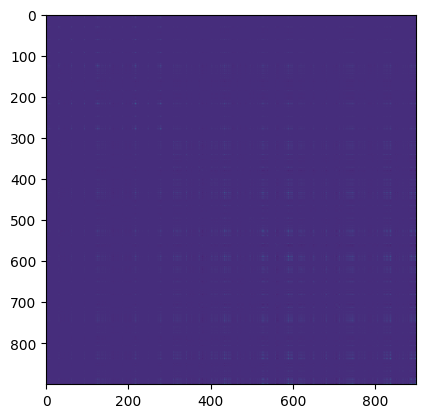

In [9]:
mol_h2 = gto.M(atom = 'H 1.32 -0.3 0; H 0.11 0.14 0.12; H -0.11 -0.3 0.4 ', symmetry=False, spin=1 )
if MAX_L >= 0  : basis_text = """
H    S
     2.0 1.0
"""
if MAX_L >= 1 :  basis_text += """
H    P
     3.0 1.0
"""
if MAX_L >= 2 :  basis_text += """
H    D
     1.0 1.0
"""
basis_text += """
END
"""
mol_h2.basis = {'H': gto.basis.parse(basis_text)}
mol_h2.build()

ijkl = mol_h2.intor("int2e_cart")
while np.isnan(ijkl).any():
    ijkl = mol_h2.intor("int2e_cart")

print('---- ATM ----')
print(mol_h2._atm)
print('---- BAS ----')
print(mol_h2._bas)
print('---- ENV ----')
print(mol_h2._env[20:])
print('---- ERI ----')
print(ijkl.shape)

atm = mol_h2._atm
bas = mol_h2._bas
env = mol_h2._env    
plt.imshow( ijkl.reshape((int(np.sqrt(ijkl.size)),-1)) )
plt.show()

In [10]:
def nc( a ):
    if a == "s": return 1
    if a == "p": return 3
    if a == "d": return 6
    assert(False)
    
def sizeof( a,b,c,d ):
    return nc(a)*nc(b)*nc(c)*nc(d)

def gen_test( shell_a, shell_b, shell_c, shell_d, mol, tol=1.e-12  ):
    
    find_z = 5
    find_c = 6
    find_atm = 0
    find_pos = 1
    find_l = 1

    def cry_l( l ):
        if l == 0 : return l
        return l+1
    
    def upF(n, z, lowerF):
        return (n-0.5)/z * lowerF - 1./(2.*z) * np.exp(-z)
    
    def loF(n, z, highrF):
        return z/(n-0.5) * highrF + np.exp(-z) / (2*(n-0.5))
    
    def F0(z):
        return  np.sqrt(np.pi) * math.erf(np.sqrt(z)) / 2 / np.sqrt(z)
    
    def zS(n):
        if n == 0:
            return 0
        p = 1
        for j in range(1,n+1):
            p *= (j-0.5)
        return (p**(1./n))
    
    fast_factorial_LOOKUP_TABLE = np.array([
        1, 1, 2, 6, 24,
        120, 720, 5040, 40320, 362880,
        3628800, 39916800, 479001600, 6227020800, 87178291200,
        1307674368000, 20922789888000, 355687428096000,
        6402373705728000, 121645100408832000, 2432902008176640000],
        dtype='int64')   
    
    NLcoset_LOOKUP_TABLE = np.array([
        1, 4, 10, 20, 35, 56, 84, 120, 165, 220, 286, 364, 455, 560, 680, 816, 969, 1140, 1330, 1540, 1771
    ],dtype='int64')
    
    NLco_LOOKUP_TABLE = np.array([
        1, 3, 6, 10, 15, 21, 28, 36, 45, 55, 66, 78, 91, 105, 120, 136, 153, 171, 190, 210, 231
    ],dtype='int64')
    
    def fast_factorial(n):
        if n > 20:
            return n*fast_factorial( (n-1) ) # not great
        return float(fast_factorial_LOOKUP_TABLE[n])
    
    def taylorF(n,k):
        if n == 0 :
            return (-1)**k / fast_factorial(k) / (2*k+1)
        return (n-1/2) * taylorF(n-1,k+1) - (-1)**(k+1) / 2 / fast_factorial(k+1)
    
    def FN(n,x,eps=10**-30,K=20):
        ret = 0
        ter = 100
        k = 0
        while abs(ter) > eps and k < K:
            ter = taylorF(n,k) * x**k
            ret += ter
            k   += 1
        return ret
    
    def compute_Fm(val,N,x):
        # if x is far enough from the origin, starts with F0 and go up
        exp_x  = np.exp(-x)
        half_sqrt_pi = np.sqrt(np.pi)/2.
        if x > zS(N):
            sqrt_x = np.sqrt(x)
            one_over_2x = 0.5/x
            val[0] = half_sqrt_pi * math.erf(sqrt_x) / sqrt_x
            for n in range(1,N+1):
                val[n] = ((2*n-1) * val[n-1] - exp_x) * one_over_2x
            return val
        val[N] = FN(N,x)
        for n in range(N-1,-1,-1):
            val[n] = (2*x*val[n+1]+exp_x) / (2*n+1)
    
    class Shell:
        def __init__(self,z,K,R,L_):
            assert(len(z)==K.shape[0])
            self.nz = len(z)
            self.nc = K.shape[1]
            self.z = z
            self.K = K
            self.R = R
            self.L = L_
    
    def K(z1,z2,R1,R2):
        normf = np.sqrt(2) * np.pi**(5./4) / (z1+z2)
        expon = - (z1*z2)/(z1+z2) * np.sum( (R1-R2)**2 )
        return normf * np.exp( expon )
        
    def orb_name( l ):
        return "spdfgh"[l]
    
    def Lcorrection(L):
        if L == 0:
            return 1.0
        elif L == 1:
            return np.sqrt(3)
        else:
            return 2 * np.sqrt(np.pi)
    
    za = mol._env[ mol._bas[shell_a][find_z] ]
    zb = mol._env[ mol._bas[shell_b][find_z] ]
    zc = mol._env[ mol._bas[shell_c][find_z] ]
    zd = mol._env[ mol._bas[shell_d][find_z] ]
    ca = mol._env[ mol._bas[shell_a][find_c] ]
    cb = mol._env[ mol._bas[shell_b][find_c] ]
    cc = mol._env[ mol._bas[shell_c][find_c] ]
    cd = mol._env[ mol._bas[shell_d][find_c] ]
    la = mol._bas[shell_a][find_l]
    lb = mol._bas[shell_b][find_l]
    lc = mol._bas[shell_c][find_l]
    ld = mol._bas[shell_d][find_l]
    a_pos_off = mol._atm[ mol._bas[shell_a][find_atm] ][find_pos]
    b_pos_off = mol._atm[ mol._bas[shell_b][find_atm] ][find_pos]
    c_pos_off = mol._atm[ mol._bas[shell_c][find_atm] ][find_pos]
    d_pos_off = mol._atm[ mol._bas[shell_d][find_atm] ][find_pos]
    A = mol._env[ a_pos_off: a_pos_off+3 ]
    B = mol._env[ b_pos_off: b_pos_off+3 ]
    C = mol._env[ c_pos_off: c_pos_off+3 ]
    D = mol._env[ d_pos_off: d_pos_off+3 ]
    int_name = "1"+orb_name(la)+" "+"1"+orb_name(lb)+"|"
    int_name += "1"+orb_name(lc)+" "+"1"+orb_name(ld)
    
    corr = Lcorrection(la)*Lcorrection(lb)*Lcorrection(lc)*Lcorrection(ld)
    ref = mol.intor_by_shell( 'int2e_cart', (shell_a,shell_b,shell_c,shell_d) ) 
    ref = ref.flatten() / ca / cb / cc / cd / corr # * 36.10813519896846 # -_-
    
    zab = za +zb
    zcd = zc +zd
    z   = zab+zcd
    P = (za*A + zb*B) / zab
    Q = (zc*C + zd*D) / zcd
    W = (zab*P + zcd*Q) / z
    PA = P-A
    WP = W-P
    QC = Q-C
    WQ = W-Q
    rho = zab*zcd/z
    L = la+lb+lc+ld
    F = np.zeros(L+1)
    T = rho * np.sum( (P-Q)**2 )
    compute_Fm(F, L, T)
    Kab = K(za,zb,A,B)
    Kcd = K(zc,zd,C,D)
    Zn = (za+zb+zc+zd)**(-0.5)/16/np.pi**2
    Kfactor = Zn * Kab * Kcd
    for m in range(L+1):
        F[m] *= Kfactor
    inv_2z   = 1./(2.*z  )
    inv_2zab = 1./(2.*zab)
    inv_2zcd = 1./(2.*zcd)
    rho_zab = rho/zab
    rho_zcd = rho/zcd
    
        
    name = orb_name(la)+orb_name(lb)+orb_name(lc)+orb_name(ld)
    cla = cry_l(la)
    clb = cry_l(lb)
    clc = cry_l(lc)
    cld = cry_l(ld)
    NC = (la+1)*(la+2)*(lb+1)*(lb+2)*(lc+1)*(lc+2)*(ld+1)*(ld+2)//16
    
    
    with np.printoptions(edgeitems=3*NC):
        P = np.array2string(P, separator=', ')[1:-1]
        Q = np.array2string(Q, separator=', ')[1:-1]
        W = np.array2string(W, separator=', ')[1:-1]
        A = np.array2string(A, separator=', ')[1:-1]
        B = np.array2string(B, separator=', ')[1:-1]
        C = np.array2string(C, separator=', ')[1:-1]
        D = np.array2string(D, separator=', ')[1:-1]
        
        F = np.array2string(F, separator=', ')[1:-1]
        ref = np.array2string(ref, separator=', ')[1:-1]
    
    filename = "gpu_int/test_"+name+"_"+str(shell_a)+str(shell_b)+str(shell_c)+str(shell_d)+".cpp"
    output_buffer = io.StringIO()   
    
    print(f"""
    #include<iostream>
    #include<vector>
    #include<cmath>
    using std::cout;
    using std::endl;
    
    #define MAXL 10
    
    enum int_Type {{
       {name} = {cla}*MAXL*MAXL*MAXL + {clb}*MAXL*MAXL + {clc}*MAXL + {cld},
    }};
    
    template< int PLW, int TS, int_Type integral_type >
    struct OS_VRR_impl;
    
    #include "{name}.h"
    
    int main (){{
    
       const double P[3] = {{ {P} }};
       const double Q[3] = {{ {Q} }};
       const double W[3] = {{ {W} }};
       const double A[3] = {{ {A} }};
       const double B[3] = {{ {B} }};
       const double C[3] = {{ {C} }};
       const double D[3] = {{ {D} }};
       const double za[1] = {{ {za} }};
       const double zb[1] = {{ {zb} }};
       const double zc[1] = {{ {zc} }};
       const double zd[1] = {{ {zd} }};
    
       const double rho[1] = {{(za[0]+zb[0])*(zc[0]+zd[0]) / ( za[0]+zb[0]+zc[0]+zd[0] )}};
    
       const double F[1+ {la}+{lb}+{lc}+{ld} ] = {{ {F} }};
       double out[{NC}] = {{0.}};
    
       OS_VRR_impl<1,1, {name} >::run ( P,Q,W, A,B,C,D, za,zb,zc,zd, rho, out, F );
    
       double ref[{NC}] = {{ {ref} }};

       bool passed = true;
    
       for ( int ijkl = 0 ; ijkl < {NC}; ijkl++ ){{
          double delta = out[ijkl] -  ref[ijkl] ;
          double ratio = 1. ; 
          if ( ref[ijkl]*ref[ijkl] > 1.e-12 ){{ ratio = out[ijkl] / ref[ijkl] ; }}
          if ( fabs(delta) > {tol} ){{ 
              passed = false;
          }}
       }}
       if ( passed ) cout << "{name} : PASSED" << endl ;
       
       if ( not passed ){{
           for ( int ijkl = 0 ; ijkl < {NC}; ijkl++ ){{
              double delta = out[ijkl] -  ref[ijkl] ;
              double ratio = 1. ; 
              if ( ref[ijkl]*ref[ijkl] > 1.e-12 ){{ ratio = out[ijkl] / ref[ijkl] ; }}
              if ( fabs(delta) > {tol} ){{ 
                  cout <<  "ERROR " ; 
              }}
              cout << ijkl << " | " << out[ijkl] << " " << ref[ijkl] << " " << delta << " " << ratio << endl;
           }}
       
       }}
    
    return passed ;
    }}""" ,  file=output_buffer )
    if L != 0:
        with open( filename, "w") as f:
            print(output_buffer.getvalue(), file = f )      
    return filename,L


In [19]:
cnt = 0
MAX_TESTS = np.infty
for shell_a in range(mol_h2.nbas):
    for shell_b in range(mol_h2.nbas):
        for shell_c in range(mol_h2.nbas):
            for shell_d in range(mol_h2.nbas):
                
                fname,L = gen_test( shell_a, shell_b, shell_c, shell_d, mol_h2, tol=1.e-8 )
                print( fname, end=" | " )
                if L != 0 :
                    compile_result = subprocess.run( "g++ "+fname+" -std=c++17", shell=True, stdout=subprocess.PIPE)
                    run_result = subprocess.run( "./a.out ", shell=True, stdout=subprocess.PIPE)
                    print(run_result.stdout)
                else :
                    print( " Skipped ssss " )
                cnt += 1
                if cnt > MAX_TESTS:
                    break
            if cnt > MAX_TESTS:
                break
        if cnt > MAX_TESTS:
            break
    if cnt > MAX_TESTS:
        break


gpu_int/test_ssss_0000.cpp |  Skipped ssss 
gpu_int/test_sssp_0001.cpp | b'Running  sssp \nsssp : PASSED\n'
gpu_int/test_sssd_0002.cpp | b'Running  sssd \nsssd : PASSED\n'
gpu_int/test_ssss_0003.cpp |  Skipped ssss 
gpu_int/test_sssp_0004.cpp | b'Running  sssp \nsssp : PASSED\n'
gpu_int/test_sssd_0005.cpp | b'Running  sssd \nsssd : PASSED\n'
gpu_int/test_ssss_0006.cpp |  Skipped ssss 
gpu_int/test_sssp_0007.cpp | b'Running  sssp \nsssp : PASSED\n'
gpu_int/test_sssd_0008.cpp | b'Running  sssd \nsssd : PASSED\n'
gpu_int/test_ssps_0010.cpp | b'Running  ssps \nssps : PASSED\n'
gpu_int/test_sspp_0011.cpp | b'Running  sspp \nsspp : PASSED\n'
gpu_int/test_sspd_0012.cpp | b'Running  sspd \nsspd : PASSED\n'
gpu_int/test_ssps_0013.cpp | b'Running  ssps \nssps : PASSED\n'
gpu_int/test_sspp_0014.cpp | b'Running  sspp \nsspp : PASSED\n'
gpu_int/test_sspd_0015.cpp | b'Running  sspd \nsspd : PASSED\n'
gpu_int/test_ssps_0016.cpp | b'Running  ssps \nssps : PASSED\n'
gpu_int/test_sspp_0017.cpp | b'Runni

In [14]:
!ls gpu_int/test_sssp_0001.cpp

gpu_int/test_sssp_0001.cpp
